# Medición de resonadores con el VNA (single sweep)

Flujo de trabajo:
1. Configurá el VNA **a mano en el panel** (centro/span, puntos, potencia, IFBW, promedios) hasta ver bien el resonador.
2. Corré la celda **Medir**: dispara UN barrido con esa configuración, lo guarda en la base QCoDeS y lo grafica.
3. El VNA vuelve solo al modo en que estaba (p.ej. continuo).

Todo se guarda en la carpeta `fluxonium_database/`. El código de adquisición está en `vna_single.py`.

In [ ]:
# --- Rutas del repositorio (celda agregada al subir a GitHub) ---
# El código está en ../codigo y las bases de datos en ../datos. Esta celda agrega ../codigo al path
# y se para en ../datos, así las rutas relativas de las bases (p. ej. 'fluxonium_2/punch_out.db')
# funcionan igual que en la PC del laboratorio. Se puede correr más de una vez.
import os, sys
from pathlib import Path
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'codigo').is_dir() and (p / 'datos').is_dir())
if str(REPO / 'codigo') not in sys.path:
    sys.path.insert(0, str(REPO / 'codigo'))
os.chdir(REPO / 'datos')
print('repo:', REPO, '| cwd:', os.getcwd())

### Imports

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import qcodes as qc
from qcodes.dataset import (initialise_or_create_database_at, load_or_create_experiment,
                            load_by_id, plot_dataset)
from qcodes.instrument_drivers.Keysight import KeysightN5245A

from vna_single import configurar_vna, medir_single, barrido_potencia, buscar_barrido, buscar_barrido_corriente, guardar_npz, traza_s21, fase_pantalla

%matplotlib inline

### Base de datos (carpeta `fluxonium_database`)

In [2]:
carpeta_db = os.path.abspath('fluxonium_2')
os.makedirs(carpeta_db, exist_ok=True)

path2database = os.path.join(carpeta_db, 'resonadores_vna.db')
initialise_or_create_database_at(path2database)
exp = load_or_create_experiment(experiment_name='resonadores', sample_name='fluxonium')
print('base:', qc.config.core.db_location)
print(exp)

base: c:\Users\Leandro\Documents\RF\rf-2026\qubits\fluxonium_2\resonadores_vna.db
resonadores#fluxonium#1@c:\Users\Leandro\Documents\RF\rf-2026\qubits\fluxonium_2\resonadores_vna.db
---------------------------------------------------------------------------------------------------
1-vna_single_all-1-f_vna,s21_mag,s21_phase,s21_re,s21_im,tr1_S21_MLOG,tr2_S21_PHAS-2406
2-vna_single_all-2-f_vna,s21_mag,s21_phase,s21_re,s21_im,tr1_S21_MLOG,tr2_S21_PHAS-2406
3-vna_single_res_q1-3-f_vna,s21_mag,s21_phase,s21_re,s21_im,tr1_S21_MLOG,tr2_S21_PHAS-1206
4-vna_single_res_q1-4-f_vna,s21_mag,s21_phase,s21_re,s21_im,tr1_S21_MLOG,tr2_S21_PHAS-2406


### Conexión al VNA

In [3]:
addr_pna = 'TCPIP::192.168.1.6::inst0::INSTR'
pna = KeysightN5245A('pna', address=addr_pna)
station = qc.Station(pna)

Connected to: Keysight Technologies N5242B (serial:MY63056409, firmware:A.15.71.08) in 0.26s


[pna_port3(KeysightPNAPort)] Snapshot: Could not update parameter: source_power
[pna_port4(KeysightPNAPort)] Snapshot: Could not update parameter: source_power
[pna_port3(KeysightPNAPort)] Snapshot: Could not update parameter: source_power
[pna_port4(KeysightPNAPort)] Snapshot: Could not update parameter: source_power


### Configurar el VNA

Cualquier parámetro en `None` no se toca (queda como está en el panel).
Al final imprime la configuración **leída del VNA** (puede redondear, p.ej. el IFBW) y el tiempo de barrido.
El VNA queda barriendo en continuo para que veas el resultado en pantalla antes de medir.

In [37]:
f_center = 6.07e9     # Hz, centro del barrido
span     = 100e6         # Hz
power    = -30          # dBm
bw       = 10          # Hz, IF bandwidth   (tiempo de barrido ~ n_points / bw)
n_points = 401          # puntos del barrido
averages = 1            # 1 = promedios apagados
edelay   = None         # s, electrical delay de la traza de fase S21 (p.ej. 62.31e-9); None = no tocar

est = configurar_vna(pna, f_center=f_center, span=span, power=power, if_bandwidth=bw,
                     points=n_points, averages=averages, edelay_fase=edelay)

LIN 6.020000-6.120000 GHz (centro 6.070000 GHz, span 100 MHz) | 401 pts | IFBW 10 Hz | P -30 dBm | prom 1 | trazas: S21/MLOG, S21/PHAS (delay 62.310 ns)
tiempo de barrido ~35.49 s


### Medir

Cambiá `resonador` / `att_vna` / `notas` antes de cada medición: quedan en la metadata del run.
- `disparar=True`: hace un barrido nuevo (respeta los promedios configurados).
- `disparar=False`: guarda lo que ya está en pantalla (VNA en HOLD), sin volver a barrer.

LIN 6.020000-6.120000 GHz (centro 6.070000 GHz, span 100 MHz) | 401 pts | IFBW 10 Hz | P -30 dBm | prom 1 | trazas: S21/MLOG, S21/PHAS (delay 62.310 ns)
Starting experimental run with id: 344. 
run_id: 344


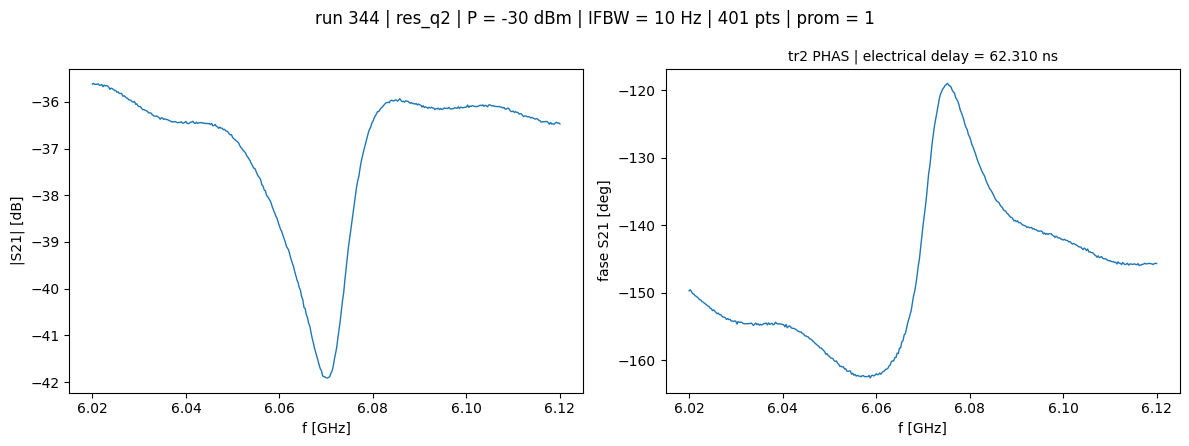

In [38]:
resonador = 'res_q2'          # etiqueta del resonador que estás midiendo
att_vna   = -31           # atenuación total de la línea de entrada [dB]
notas     = 'resonador del qubit Q2 (Guri)'            # comentario libre
disparar  = True

r = medir_single(pna, disparar=disparar, nombre=f'vna_single_{resonador}', graficar=False,
                 att_vna=att_vna, resonador=resonador, notas=notas)

# ---------------- gráfico (como lo muestra el VNA) ----------------
est = r['estado']
f = r['x'] / 1e9                                       # GHz
mag = 20 * np.log10(np.abs(traza_s21(r)['sdata']))     # |S21| [dB]
fase, edelay, origen = fase_pantalla(r)                # fase [deg] con el electrical delay del VNA

fig, (ax_m, ax_p) = plt.subplots(1, 2, figsize=(12, 4.5), sharex=True)
ax_m.plot(f, mag, lw=1)
ax_m.set_xlabel('f [GHz]'); ax_m.set_ylabel('|S21| [dB]')
ax_p.plot(f, fase, lw=1)
ax_p.set_xlabel('f [GHz]'); ax_p.set_ylabel('fase S21 [deg]')
ax_p.set_title(f'{origen} | electrical delay = {edelay * 1e9:.3f} ns', fontsize=10)

prom = est['averages'] if est['averages_enabled'] else 1
fig.suptitle(f"run {r['run_id']} | {resonador} | P = {est['power']:g} dBm | "
             f"IFBW = {est['if_bandwidth']:g} Hz | {est['points']} pts | prom = {prom}")
fig.tight_layout()
plt.show()

### Volver a cargar un run guardado

In [ ]:
run_id = r['run_id']          # o un número, p.ej. 12
ds = load_by_id(run_id)
print(ds.name, '|', {k: ds.metadata[k] for k in ('resonador', 'pow_vna', 'bw_vna', 'att_vna') if k in ds.metadata})

d = ds.get_parameter_data()
f_db = d['s21_mag']['f_vna'] / 1e9

# fase como en el VNA: la traza de fase S21 guardada (tr*_S21_PHAS / UPH / PPH)
k_fase = next((k for k in d if '_S21_' in k and k.split('_')[-1] in ('PHAS', 'UPH', 'PPH')), None)
if k_fase is not None:
    fase_db = d[k_fase][k_fase]
else:   # no había traza de fase en pantalla: datos complejos + electrical delay
    z_db = d['s21_re']['s21_re'] + 1j * d['s21_im']['s21_im']
    tau = float(ds.metadata.get('electrical_delay', 0))
    fase_db = np.rad2deg(np.angle(z_db * np.exp(2j * np.pi * d['s21_re']['f_vna'] * tau)))

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5), sharex=True)
ax[0].plot(f_db, d['s21_mag']['s21_mag'], lw=1); ax[0].set_ylabel('|S21| [dB]')
ax[1].plot(f_db, fase_db, lw=1); ax[1].set_ylabel('fase S21 [deg]')
for a in ax: a.set_xlabel('f [GHz]')
fig.suptitle(f'run {run_id} (leído de la base)'); fig.tight_layout(); plt.show()

# todas las variables guardadas (una figura por parámetro):
# axes, cbars = plot_dataset(ds)

### (Opcional) Ajuste rápido con `fit_resonancia.py`

run 344
  fr     = 6.0726661 GHz ± 67.43 kHz
  κ/2π   = 15813.23 kHz   (κi/2π = 8197.09, κc/2π = 7616.14 kHz)
  Ql     = 384 ± 3.3
  Qi     = 740.8 ± 7.8
  Qc     = 797.3 ± 7.7   (|Qc| = 691.2, φ0 = -0.522 rad)
  caída  = 6.13 dB,  delay = 63.11 ns
  res/noise = 4.77  (ok)
  P_VNA = -30.0 dBm, att = -31.0 dB -> P_in = -61.0 dBm
  <n>    = 1.91e+06 fotones   (<n> = 1 en P_in ≈ -123.8 dBm)


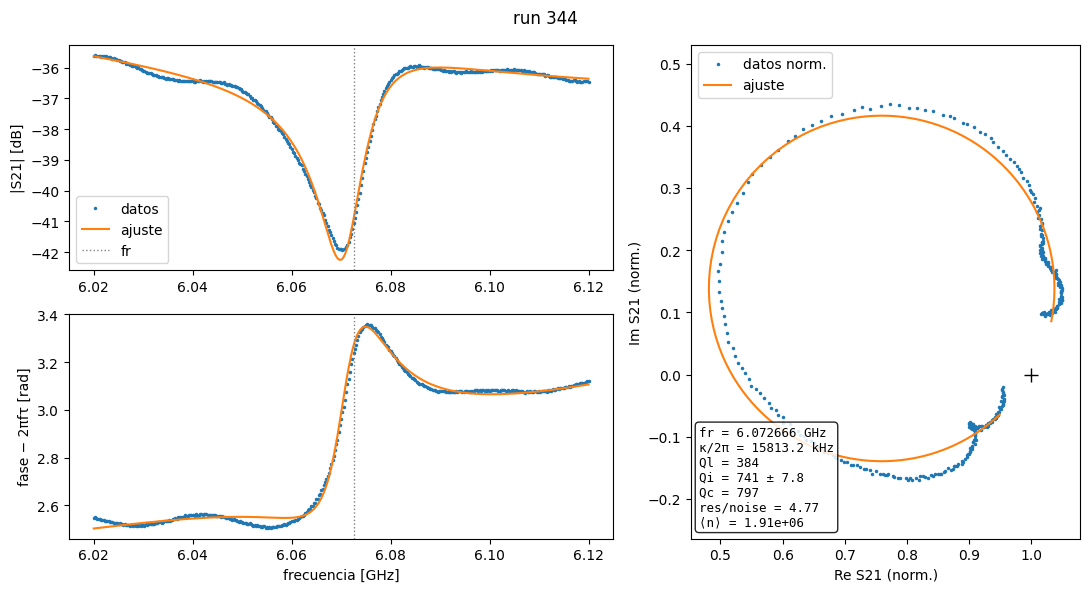

In [39]:
from qcodes.dataset import load_by_id
from fit_resonancia import ajustar_resonancia

run_id = r['run_id']                      # o un número, p.ej. 3
att = load_by_id(run_id).metadata['att_vna']
res = ajustar_resonancia(path2database, run_id, att_total=att)

## Barrido en potencia

Mide el resonador a varias potencias del VNA (un run por potencia) y después ajusta cada traza para ver
**fr, Qi, Qc y la profundidad del dip en función de la potencia / ⟨n⟩**.

Antes de correrlo:
- Centrá el resonador con la celda **Configurar el VNA**, con un span de al menos ~10 anchos de línea (κ) y ≥ 400 puntos.
  Centro, span y puntos quedan fijos durante todo el barrido; solo cambian la potencia (y, si querés, el IFBW o los promedios).
- Andá de **menor a mayor** potencia: a potencia alta el resonador puede volverse no lineal.
- A baja potencia la señal es chica: bajá el IFBW o promediá (`ifbw_b` / `avg_b` pueden depender de la potencia).
- Al terminar, el VNA vuelve a la potencia, IFBW, promedios y modo que tenía.

30 potencias, duración estimada ~20.1 min
barrido 20261107_204039: 30 potencias de -30 a -1 dBm
Starting experimental run with id: 345. 
  1/30 | P =  -30.0 dBm | IFBW 10 Hz | prom 1 | run 345 | 0.6 min, faltan ~18.2 min
Starting experimental run with id: 346. 
  2/30 | P =  -29.0 dBm | IFBW 10 Hz | prom 1 | run 346 | 1.2 min, faltan ~17.5 min
Starting experimental run with id: 347. 
  3/30 | P =  -28.0 dBm | IFBW 10 Hz | prom 1 | run 347 | 1.9 min, faltan ~17.1 min
Starting experimental run with id: 348. 
  4/30 | P =  -27.0 dBm | IFBW 10 Hz | prom 1 | run 348 | 2.6 min, faltan ~16.7 min
Starting experimental run with id: 349. 
  5/30 | P =  -26.0 dBm | IFBW 10 Hz | prom 1 | run 349 | 3.2 min, faltan ~16.1 min
Starting experimental run with id: 350. 
  6/30 | P =  -25.0 dBm | IFBW 10 Hz | prom 1 | run 350 | 3.9 min, faltan ~15.4 min
Starting experimental run with id: 351. 
  7/30 | P =  -24.0 dBm | IFBW 10 Hz | prom 1 | run 351 | 4.5 min, faltan ~14.7 min
Starting experimental run wit

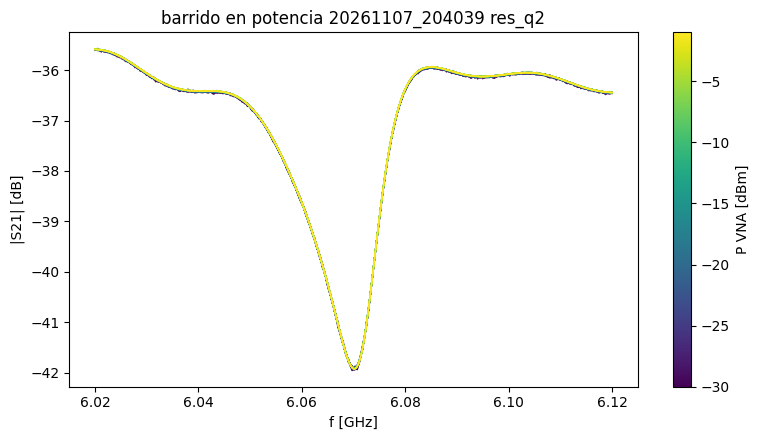

In [40]:
potencias = np.arange(-30, 0, 1)      # dBm en el VNA, de menor a mayor
ifbw_b    = 10                       # Hz: None = el configurado, un número, o una función de p:
# ifbw_b  = lambda p: 10 if p < -20 else 100
avg_b     = 1                       # promedios: None, un número, o una función de p

# duración estimada (~ puntos / IFBW por barrido, sin contar promedios)
n_pts = pna.points()
bw_de = lambda p: (ifbw_b(p) if callable(ifbw_b) else ifbw_b) or pna.if_bandwidth()
print(f'{len(potencias)} potencias, duración estimada ~{sum(n_pts / bw_de(p) for p in potencias) / 60:.1f} min')

bp = barrido_potencia(pna, potencias, ifbw=ifbw_b, averages=avg_b,
                      resonador=resonador, att_vna=att_vna, notas=notas)

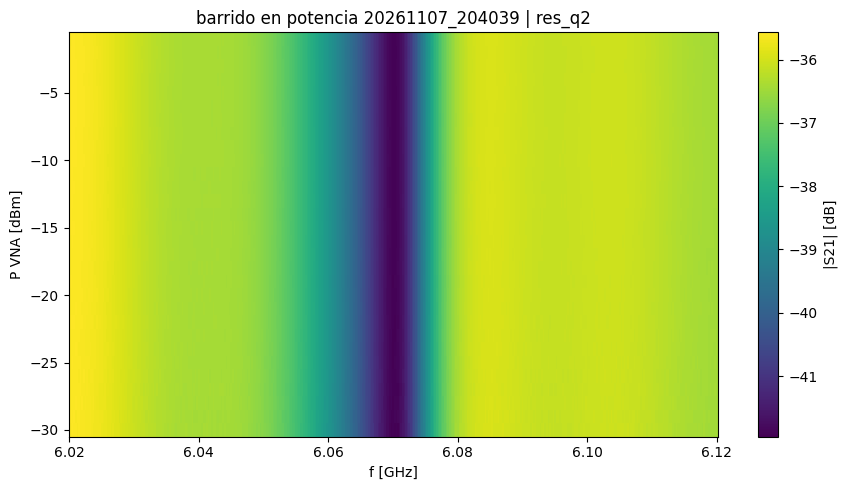

In [41]:
# ---------------- mapa |S21|(f, P) del barrido en potencia ----------------
bp = buscar_barrido('20261107_204039')     # para graficar un barrido viejo por su tag

pots, mags, f_map = [], [], None
for x in bp['runs']:
    ds_i = load_by_id(x['run_id'])
    d_i = ds_i.get_parameter_data()['s21_mag']
    f_i = d_i['f_vna']
    if f_map is None:
        f_map = f_i
    elif len(f_i) != len(f_map) or not np.allclose(f_i, f_map):
        raise ValueError(f"run {x['run_id']}: eje de frecuencia distinto al resto del barrido")
    pots.append(float(ds_i.metadata['pow_vna']))
    mags.append(d_i['s21_mag'])

orden = np.argsort(pots)
P_map = np.array(pots)[orden]
S_map = np.array(mags)[orden]               # filas = potencias, columnas = frecuencias

fig, ax = plt.subplots(figsize=(9, 5))
pc = ax.pcolormesh(f_map / 1e9, P_map, S_map, shading='nearest', cmap='viridis')
fig.colorbar(pc, ax=ax, label='|S21| [dB]')
ax.set_xlabel('f [GHz]'); ax.set_ylabel('P VNA [dBm]')
ax.set_title(f"barrido en potencia {bp['barrido']} | {resonador}")
fig.tight_layout()
plt.show()

### Ajuste del barrido en potencia

Ajusta cada run con `fit_resonancia` y arma una tabla (también se guarda como `.csv` en la carpeta de la base).
- `att_total`: atenuación total hasta el resonador, para calcular ⟨n⟩.
- `fcrop`: `'auto'` (dip ± 4 anchos) o `(f1, f2)` en Hz para usar la misma ventana en todas las potencias.
- Para recuperar un barrido viejo (p.ej. después de reiniciar el kernel): `bp = buscar_barrido('<tag>')`; el tag se imprime al medir.

Cómo leerlo: si **Qi sube con la potencia**, las pérdidas son por defectos de los materiales (TLS) y a más potencia el dip se profundiza.
Si **fr se corre** o la columna `res_noise` crece mucho a potencia alta, el resonador ya no es lineal (o el qubit hace *punch-out*):
esos puntos no sirven para el ajuste Lorentziano.

tabla guardada en c:\Users\Leandro\Documents\RF\rf-2026\qubits\fluxonium_2\barrido_20261107_204039_res_q2.csv


,run_id,P_vna,P_in_dBm,n_fotones,fr,fr_err,Ql,Ql_err,Qi,Qi_err,Qc,Qc_err,phi0,caida_db,res_noise,ok
0,345,-30.0,-111.0,19.204510,6.072677e+09,67157.559623,384.846229,3.315654,743.321224,7.852423,798.003694,7.652162,-0.522666,6.139615,4.802977,True
1,346,-29.0,-110.0,24.075946,6.072666e+09,67611.594914,383.437550,3.310940,740.237079,7.830224,795.501868,7.648010,-0.521679,6.133286,4.871804,True
2,347,-28.0,-109.0,30.355533,6.072676e+09,67855.728111,384.266581,3.337789,741.389692,7.890413,797.739695,7.713645,-0.522136,6.128511,5.047959,True
3,348,-27.0,-108.0,38.324696,6.072673e+09,67326.307367,384.730052,3.322027,743.425403,7.872984,797.384449,7.656612,-0.521520,6.141648,5.064084,True
4,349,-26.0,-107.0,48.052571,6.072675e+09,67499.128438,383.789594,3.309955,740.497923,7.824248,796.716460,7.650515,-0.521975,6.128578,5.170166,True
5,350,-25.0,-106.0,60.651124,6.072671e+09,67590.872279,384.380299,3.327083,742.358857,7.878036,797.109526,7.677369,-0.521919,6.137488,5.185447,True
6,351,-24.0,-105.0,76.323032,6.072680e+09,67342.058400,384.454336,3.314772,742.079250,7.843675,797.750870,7.658956,-0.522894,6.133967,5.288426,True
7,352,-23.0,-104.0,96.079048,6.072672e+09,67827.651769,384.358474,3.338881,742.021924,7.900896,797.404414,7.709012,-0.522043,6.134030,5.330629,True
8,353,-22.0,-103.0,121.023144,6.072677e+09,67203.252134,384.531960,3.310222,742.427509,7.835289,797.682750,7.644092,-0.522563,6.135848,5.361196,True
9,354,-21.0,-102.0,152.498432,6.072675e+09,67261.029658,384.751626,3.317434,743.088359,7.857563,797.865326,7.653045,-0.521988,6.137766,5.404972,True


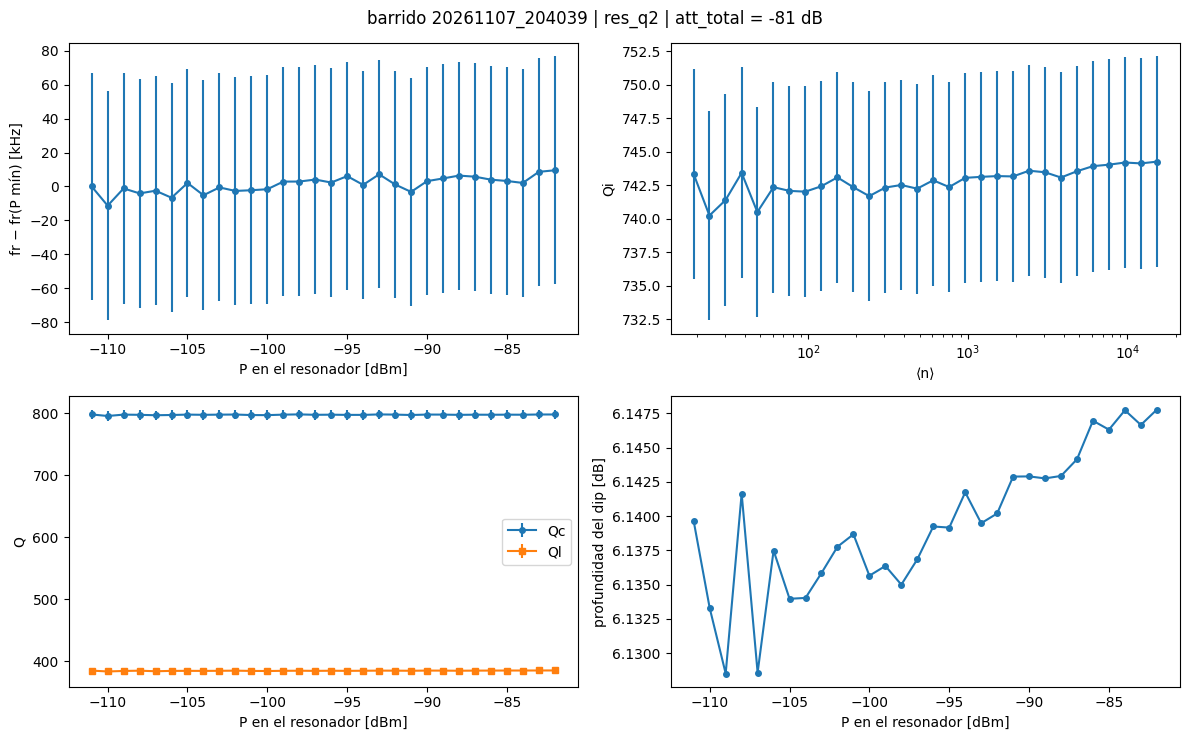

In [42]:
import pandas as pd
from fit_resonancia import ajustar_resonancia

bp = buscar_barrido('20261107_204039')      # para recuperar un barrido viejo por su tag
att_total = att_vna - 50     # atenuación total hasta el resonador [dB] (para <n>)
fcrop     = 'auto'      # o (f1, f2) en Hz

filas = []
for x in bp['runs']:
    try:
        filas.append(ajustar_resonancia(path2database, x['run_id'], att_total=att_total, fcrop=fcrop,
                                        graficar=False, imprimir=False))
    except Exception as e:
        print(f"run {x['run_id']} (P = {x['power']:g} dBm): no ajustó -> {e}")

cols = ['run_id', 'P_vna', 'P_in_dBm', 'n_fotones', 'fr', 'fr_err', 'Ql', 'Ql_err', 'Qi', 'Qi_err',
        'Qc', 'Qc_err', 'phi0', 'caida_db', 'res_noise', 'ok']
tabla = pd.DataFrame(filas).reindex(columns=cols).sort_values('P_vna').reset_index(drop=True)
path_csv = os.path.join(carpeta_db, f"barrido_{bp['barrido']}_{resonador}.csv")
tabla.to_csv(path_csv, index=False)
print('tabla guardada en', path_csv)
display(tabla)

# ---------------- gráficos ----------------
con_n = tabla['n_fotones'].notna().all()
xk, xlab = ('P_in_dBm', 'P en el resonador [dBm]') if con_n else ('P_vna', 'P VNA [dBm]')
x = tabla[xk]
fig, ax = plt.subplots(2, 2, figsize=(12, 7.5))

ax[0, 0].errorbar(x, (tabla['fr'] - tabla['fr'].iloc[0]) / 1e3, yerr=tabla['fr_err'] / 1e3, fmt='o-', ms=4)
ax[0, 0].set_ylabel('fr − fr(P mín) [kHz]'); ax[0, 0].set_xlabel(xlab)

xn = tabla['n_fotones'] if con_n else x
ax[0, 1].errorbar(xn, tabla['Qi'], yerr=tabla['Qi_err'], fmt='o-', ms=4)
ax[0, 1].set_ylabel('Qi'); ax[0, 1].set_xlabel('⟨n⟩' if con_n else xlab)
if con_n:
    ax[0, 1].set_xscale('log')

ax[1, 0].errorbar(x, tabla['Qc'], yerr=tabla['Qc_err'], fmt='o-', ms=4, label='Qc')
ax[1, 0].errorbar(x, tabla['Ql'], yerr=tabla['Ql_err'], fmt='s-', ms=4, label='Ql')
ax[1, 0].set_ylabel('Q'); ax[1, 0].set_xlabel(xlab); ax[1, 0].legend()

ax[1, 1].plot(x, tabla['caida_db'], 'o-', ms=4)
ax[1, 1].set_ylabel('profundidad del dip [dB]'); ax[1, 1].set_xlabel(xlab)

malos = tabla[~tabla['ok'].astype(bool)]
if len(malos):
    print('⚠ ajustes dudosos en P_vna =', list(malos['P_vna']))

fig.suptitle(f"barrido {bp['barrido']} | {resonador} | att_total = {att_total} dB")
fig.tight_layout()
plt.show()

## Barrido en potencia para cada corriente de la bobina (búsqueda de punch-out)

Para cada corriente de la bobina (es decir, cada valor de flujo) hace un **barrido en potencia completo** con el VNA.
Cada potencia de cada corriente es un run propio en la base, con metadata `current_uA`, `barrido` (tag del barrido en
potencia de esa corriente) y `barrido_corriente` (tag de toda la medición).

Qué buscar después: a potencia baja el resonador está "vestido" por el qubit y su frecuencia **depende de la corriente**;
si a potencia alta hay punch-out, el dip salta a la frecuencia sin qubit, que **no depende de la corriente**.

Antes de correr:
- Configurá centro / span / puntos con la celda **Configurar el VNA** (span de al menos ~10 κ, que abarque el corrimiento esperado).
- Duración ≈ n° de corrientes × (suma de los tiempos de barrido de todas las potencias): se imprime una estimación al empezar.

### Fuente de corriente de la bobina

In [23]:
import time
import pyvisa

class KeithleyCurrentSource:
    """Fuente de corriente de la bobina (mismos comandos que en readout.ipynb)."""
    def __init__(self, inst):
        self.inst = inst
        self.ultima = None              # última corriente seteada [A]

    def set_current(self, I):
        self.inst.write(f'I{I:.4e}X')
        self.ultima = float(I)

    def get_current(self):
        return float(self.inst.query('CURR?').split(',')[0][4:])


def rampa_corriente(objetivo, paso=1e-6, espera=0.05):
    """Lleva la corriente al objetivo en pasos chicos (evita saltos de flujo). paso=None: directo."""
    if paso is None:
        keithley.set_current(float(objetivo)); return
    actual = keithley.ultima
    if actual is None:
        try:
            actual = keithley.get_current()
        except Exception:
            actual = 0.0
    n = max(int(np.ceil(abs(objetivo - actual) / paso)), 1)
    for i_ in np.linspace(actual, objetivo, n + 1)[1:]:
        keithley.set_current(float(i_)); time.sleep(espera)


rm = pyvisa.ResourceManager()
keithley = KeithleyCurrentSource(rm.open_resource('GPIB0::15::INSTR'))

### Medición: barrido en potencia × corriente

In [34]:
corrientes  = np.arange(0e-6, 0.05e-6, 0.005e-6)   # A, valores de corriente de la bobina
potencias_I = np.arange(-30, -4, 1)                       # dBm en el VNA, de menor a mayor
ifbw_I      = 10       # Hz: None = el configurado, un número, o función de p (p.ej. lambda p: 10 if p < -20 else 100)
avg_I       = 1       # promedios: None, un número, o función de p
wait_I      = 0.5        # s, espera después de llegar a cada corriente
paso_rampa  = 1e-6       # A, paso de la rampa entre corrientes (None = salto directo)
volver_a_cero = False    # al terminar, rampa la corriente a 0

# duración estimada (~ puntos / IFBW por barrido, sin promedios)
n_pts = pna.points()
bw_de = lambda p: (ifbw_I(p) if callable(ifbw_I) else ifbw_I) or pna.if_bandwidth()
t_pot = sum(n_pts / bw_de(p) for p in potencias_I)
print(f'{len(corrientes)} corrientes x {len(potencias_I)} potencias | '
      f'~{t_pot / 60:.1f} min por corriente, ~{len(corrientes) * t_pot / 3600:.1f} h en total')

tag_I = time.strftime('%Y%m%d_%H%M%S')
bc = dict(barrido_corriente=tag_I, barridos=[])
print(f"barrido_corriente = '{tag_I}'   (para recuperarlo: buscar_barrido_corriente('{tag_I}'))")
t0 = time.time()
try:
    for k, I in enumerate(corrientes):
        rampa_corriente(I, paso=paso_rampa)
        time.sleep(wait_I)
        b = barrido_potencia(pna, potencias_I, ifbw=ifbw_I, averages=avg_I, resonador=resonador,
                             graficar=False, verbose=False, tag=f'{tag_I}_I{k:03d}',
                             att_vna=att_vna, notas=notas, current_uA=I * 1e6,
                             barrido_corriente=tag_I, barrido_corriente_idx=k)
        bc['barridos'].append(dict(current_uA=I * 1e6, **b))
        el = time.time() - t0
        falta = el / (k + 1) * (len(corrientes) - k - 1)
        print(f"  {k + 1}/{len(corrientes)} | I = {I * 1e6:8.3f} uA | runs {b['runs'][0]['run_id']}-{b['runs'][-1]['run_id']}"
              f" | {el / 60:.1f} min, faltan ~{falta / 60:.1f} min")
finally:
    if volver_a_cero:
        rampa_corriente(0.0, paso=paso_rampa)
print('listo')

10 corrientes x 26 potencias | ~17.4 min por corriente, ~2.9 h en total
barrido_corriente = '20261107_145543'   (para recuperarlo: buscar_barrido_corriente('20261107_145543'))
barrido 20261107_145543: 26 potencias de -30 a -5 dBm
Starting experimental run with id: 84. 
  1/26 | P =  -30.0 dBm | IFBW 10 Hz | prom 1 | run 84 | 0.7 min, faltan ~16.3 min
Starting experimental run with id: 85. 
  2/26 | P =  -29.0 dBm | IFBW 10 Hz | prom 1 | run 85 | 1.3 min, faltan ~15.5 min
Starting experimental run with id: 86. 
  3/26 | P =  -28.0 dBm | IFBW 10 Hz | prom 1 | run 86 | 1.9 min, faltan ~14.7 min
Starting experimental run with id: 87. 
  4/26 | P =  -27.0 dBm | IFBW 10 Hz | prom 1 | run 87 | 2.5 min, faltan ~14.0 min
Starting experimental run with id: 88. 
  5/26 | P =  -26.0 dBm | IFBW 10 Hz | prom 1 | run 88 | 3.2 min, faltan ~13.3 min
Starting experimental run with id: 89. 
  6/26 | P =  -25.0 dBm | IFBW 10 Hz | prom 1 | run 89 | 3.8 min, faltan ~12.7 min
Starting experimental run with i

### Gráficos del barrido en potencia × corriente

1. Un mapa |S21|(f, P) por corriente.
2. Frecuencia del mínimo del dip vs potencia, una curva por corriente: **un salto en alguna potencia es la firma del punch-out**.
   Si a potencia alta las curvas de todas las corrientes convergen a la misma frecuencia, esa es la frecuencia sin qubit.

`normalizar = True` resta la mediana de cada traza: quita cambios de nivel de fondo (p.ej. saturación del amplificador
a potencia alta) y deja solo la forma del dip.

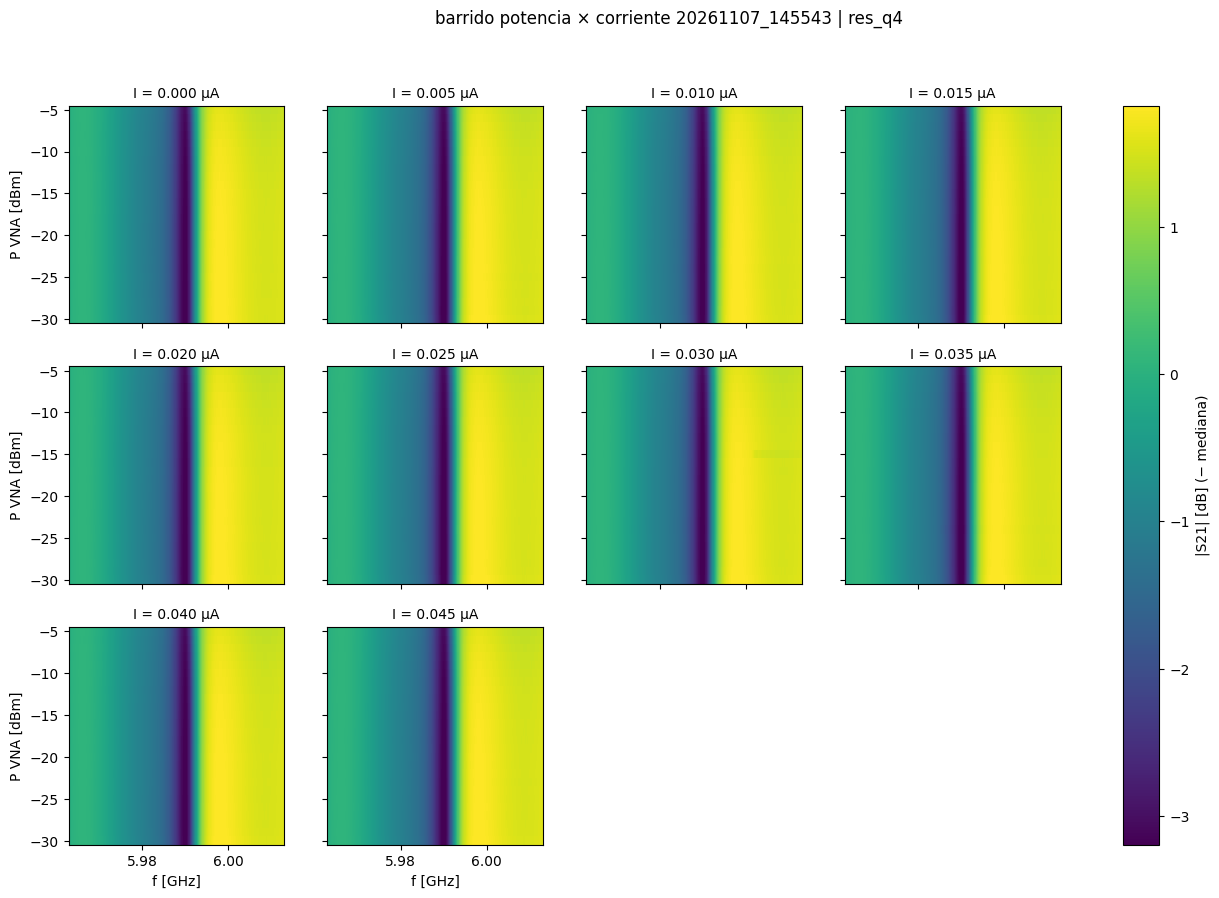

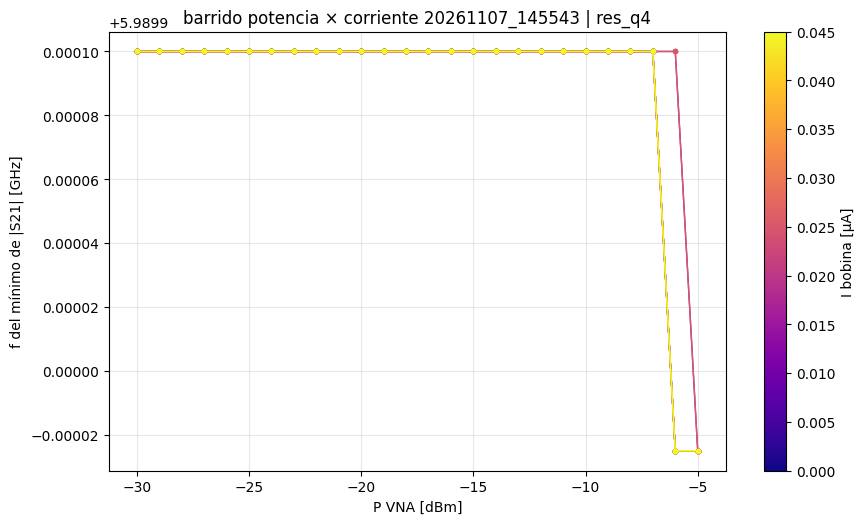

In [36]:
# bc = buscar_barrido_corriente('20261107_150000')     # para recuperar una medición vieja por su tag
normalizar = True

def f_del_minimo(f, s, n=5):
    """Frecuencia del mínimo de |S21| (suavizado con media móvil de n puntos)."""
    s_s = np.convolve(s, np.ones(n) / n, mode='same')
    return f[np.argmin(s_s[n:-n]) + n]

datos = []                                  # (I [uA], P [dBm], f [Hz], S [dB] con filas = potencias)
for b in bc['barridos']:
    pots, mags, f_b = [], [], None
    for x in b['runs']:
        ds_i = load_by_id(x['run_id'])
        d_i = ds_i.get_parameter_data()['s21_mag']
        pots.append(float(ds_i.metadata['pow_vna']))
        mags.append(d_i['s21_mag'])
        f_b = d_i['f_vna']
    o = np.argsort(pots)
    S = np.array(mags)[o]
    if normalizar:
        S = S - np.median(S, axis=1, keepdims=True)
    datos.append((float(b['current_uA']), np.array(pots)[o], f_b, S))
datos.sort(key=lambda d: d[0])

# ---- 1) mapas |S21|(f, P), uno por corriente ----
n = len(datos)
ncol = min(4, n)
nfil = int(np.ceil(n / ncol))
vmin = min(np.percentile(d[3], 1) for d in datos)
vmax = max(np.percentile(d[3], 99) for d in datos)
fig1, axs = plt.subplots(nfil, ncol, figsize=(4 * ncol, 3.2 * nfil), sharex=True, sharey=True, squeeze=False)
for a, (I_uA, P, f_b, S) in zip(axs.flat, datos):
    pc = a.pcolormesh(f_b / 1e9, P, S, shading='nearest', cmap='viridis', vmin=vmin, vmax=vmax)
    a.set_title(f'I = {I_uA:.3f} µA', fontsize=10)
for a in axs.flat[n:]:
    a.set_visible(False)
for a in axs[-1]:
    a.set_xlabel('f [GHz]')
for a in axs[:, 0]:
    a.set_ylabel('P VNA [dBm]')
fig1.colorbar(pc, ax=axs, label='|S21| [dB]' + (' (− mediana)' if normalizar else ''))
fig1.suptitle(f"barrido potencia × corriente {bc['barrido_corriente']} | {resonador}")
plt.show()

# ---- 2) frecuencia del mínimo vs potencia, una curva por corriente ----
cmap_I = plt.get_cmap('plasma')
norm_I = plt.Normalize(datos[0][0], datos[-1][0])
fig2, ax2 = plt.subplots(figsize=(9, 5.5))
for I_uA, P, f_b, S in datos:
    fmin = np.array([f_del_minimo(f_b, s) for s in S])
    ax2.plot(P, fmin / 1e9, 'o-', ms=3, lw=1, color=cmap_I(norm_I(I_uA)))
fig2.colorbar(plt.cm.ScalarMappable(norm=norm_I, cmap=cmap_I), ax=ax2, label='I bobina [µA]')
ax2.set_xlabel('P VNA [dBm]'); ax2.set_ylabel('f del mínimo de |S21| [GHz]')
ax2.set_title(f"barrido potencia × corriente {bc['barrido_corriente']} | {resonador}")
ax2.grid(alpha=0.3)
fig2.tight_layout()
plt.show()

### Cerrar la conexión al terminar

In [43]:
pna.close()